In [1]:
!pip install -q transformers==4.46.3 datasets==3.1.0 evaluate jiwer accelerate librosa soundfile

In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is still unavailable.")

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [8]:
import os

print(os.listdir("/content/drive/MyDrive"))

['Classroom', 'Video', 'Exam result', 'Edited - IMG-20230811-WA0018.jpeg', 'IMG-20231119-WA0067.jpg', 'Screenshot_2023-12-04-22-08-05-465_com.whatsapp.jpg', 'Colab Notebooks', 'Fast-Dreambooth', '4SN22AI062', 'For use', 'Math1', 'CV EL HOUFIA Oumaima V English.pdf', 'CV EL HOUFIA Oumaima V English.gdoc', 'Screenshot_2024-05-27-15-43-35-228_com.google.android.apps.nbu.paisa.user.jpg', 'My things', 'VAP udupi.pdf', 'Screenshot_2024-11-01-11-03-09-253_com.google.android.apps.nbu.paisa.user.jpg', 'EVS_Vrushali.docx', 'EVS_Vrushali[4SN22AI062].docx', 'cognify internship WORKBOOKTASK 1.zip', 'ACE Scanner_2025_03_06 (1).pdf', 'ACE Scanner_2025_03_06.pdf', 'Drone Collection.gsheet', 'vrushali sem6.pdf', 'IMG_20250806_135155 (1).jpg', 'IMG_20250806_135155.jpg', 'Vrushali A P photo (4).jpg', 'VAP (4).jpg', 'VAP (3).jpg', 'Vrushali A P photo (3).jpg', 'Vrushali A P photo (2).jpg', 'VAP (2).jpg', 'Vrushali A P photo (1).jpg', 'Vrushali A P photo.jpg', 'Vrushali A Poojary.jpg', 'VAP (1).jpg', 'VAP.

In [9]:
BASE_IN = "/content/drive/MyDrive/data"

print("Data folder accessible:", os.path.exists(BASE_IN))

if os.path.exists(BASE_IN):
    print(os.listdir(BASE_IN))

Data folder accessible: True
['converted', 'pilot_processed', 'splits', 'data', 'pilot_splits', 'data (1)', 'data (1) (1)']


In [10]:
import os

BASE_IN = "/content/drive/MyDrive/data"
BASE_OUT = "/content/drive/MyDrive/SwissDial_ASR_Output"

os.makedirs(BASE_OUT, exist_ok=True)

print("Original audio dialect folders:")
print(os.listdir(os.path.join(BASE_IN, "converted")))

print("\nOriginal split files:")
print(os.listdir(os.path.join(BASE_IN, "splits")))

print("\nNew account output folder:")
print(BASE_OUT)

Original audio dialect folders:
['ag', 'zh', 'sg', 'gr', 'vs', 'bs', 'lu', 'be']

Original split files:
['train.csv', 'test.csv', 'validation.csv']

New account output folder:
/content/drive/MyDrive/SwissDial_ASR_Output


In [11]:
import os
import json
from datetime import datetime

# Original dataset in the shared old Google Drive
BASE_IN = "/content/drive/MyDrive/data"

# Permanent project storage in the new Google Drive
BASE_OUT = "/content/drive/MyDrive/SwissDial_ASR_Output"

# Create project folders
folders = [
    "config",
    "pilot_splits",
    "processed/train",
    "processed/validation",
    "checkpoints",
    "final_model",
    "results",
    "logs"
]

for folder in folders:
    os.makedirs(os.path.join(BASE_OUT, folder), exist_ok=True)

# Create project status without overwriting existing progress
status_file = os.path.join(BASE_OUT, "project_status.json")

if not os.path.exists(status_file):
    status = {
        "project": "Swiss German ASR",
        "base_model": "openai/whisper-base",
        "dataset": "SwissDial",
        "stage": "storage_setup",
        "preprocessing_completed": False,
        "training_completed": False,
        "last_checkpoint": None,
        "last_updated": datetime.now().isoformat()
    }

    with open(status_file, "w") as f:
        json.dump(status, f, indent=4)

print("PROJECT STORAGE READY")
print("---------------------")
print("Input folder exists:", os.path.exists(BASE_IN))
print("Output folder:", BASE_OUT)
print("\nCreated/verified folders:")

for folder in folders:
    print("✓", folder)

print("\nProject status file:", os.path.exists(status_file))

PROJECT STORAGE READY
---------------------
Input folder exists: True
Output folder: /content/drive/MyDrive/SwissDial_ASR_Output

Created/verified folders:
✓ config
✓ pilot_splits
✓ processed/train
✓ processed/validation
✓ checkpoints
✓ final_model
✓ results
✓ logs

Project status file: True


In [12]:
import os
import pandas as pd

BASE_IN = "/content/drive/MyDrive/data"
BASE_OUT = "/content/drive/MyDrive/SwissDial_ASR_Output"

os.makedirs(BASE_OUT, exist_ok=True)

# Load existing pilot splits
pilot_train = pd.read_csv(
    f"{BASE_IN}/pilot_splits/pilot_train.csv"
)

pilot_validation = pd.read_csv(
    f"{BASE_IN}/pilot_splits/pilot_validation.csv"
)

# Correct audio paths
def fix_paths(df):
    df = df.copy()
    df["audio_path"] = df.apply(
        lambda row: os.path.join(
            BASE_IN,
            "converted",
            str(row["dialect"]),
            os.path.basename(str(row["audio_path"]).replace("\\", "/"))
        ),
        axis=1
    )
    return df

pilot_train = fix_paths(pilot_train)
pilot_validation = fix_paths(pilot_validation)

print("Training:", len(pilot_train))
print("Validation:", len(pilot_validation))
print("Training dialects:", pilot_train["dialect"].nunique())
print("Validation dialects:", pilot_validation["dialect"].nunique())

Training: 500
Validation: 100
Training dialects: 8
Validation dialects: 8


In [13]:
import os
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
from datasets import Dataset, load_from_disk, concatenate_datasets
from transformers import WhisperProcessor

# Load Whisper Base processor
processor = WhisperProcessor.from_pretrained(
    "openai/whisper-base",
    language="German",
    task="transcribe"
)

# Persistent output folders
PROCESSED_DIR = f"{BASE_OUT}/processed"
os.makedirs(PROCESSED_DIR, exist_ok=True)

# Find the transcript column
possible_text_columns = ["text", "transcript", "transcription", "sentence"]
TEXT_COL = next(
    (c for c in possible_text_columns if c in pilot_train.columns),
    None
)

if TEXT_COL is None:
    raise ValueError(f"Transcript column not found. Available columns: {list(pilot_train.columns)}")

def preprocess_split(df, split_name, batch_size=50):
    split_dir = f"{PROCESSED_DIR}/{split_name}"
    os.makedirs(split_dir, exist_ok=True)

    saved_chunks = []

    for start in range(0, len(df), batch_size):
        end = min(start + batch_size, len(df))
        chunk_dir = f"{split_dir}/chunk_{start}_{end}"

        if os.path.exists(chunk_dir):
            print(f"Reusing saved {split_name} batch {start}-{end}")
            saved_chunks.append(load_from_disk(chunk_dir))
            continue

        records = []

        for _, row in df.iloc[start:end].iterrows():
            audio, sr = sf.read(row["audio_path"])

            if audio.ndim == 2:
                audio = audio.mean(axis=1)

            if sr != 16000:
                audio = librosa.resample(
                    audio.astype(np.float32),
                    orig_sr=sr,
                    target_sr=16000
                )

            audio = audio.astype(np.float32)

            features = processor.feature_extractor(
                audio,
                sampling_rate=16000
            ).input_features[0]

            labels = processor.tokenizer(
                str(row[TEXT_COL])
            ).input_ids

            records.append({
                "input_features": features.tolist(),
                "labels": labels
            })

        chunk = Dataset.from_list(records)
        chunk.save_to_disk(chunk_dir)
        saved_chunks.append(chunk)

        print(f"Saved {split_name}: {end}/{len(df)} recordings")

    final_dataset = concatenate_datasets(saved_chunks)
    final_dataset.save_to_disk(f"{PROCESSED_DIR}/{split_name}_complete")

    print(f"\n{split_name} preprocessing complete: {len(final_dataset)} recordings")
    return final_dataset

train_dataset = preprocess_split(pilot_train, "train")
validation_dataset = preprocess_split(pilot_validation, "validation")

print("\nBoth datasets are saved permanently in Google Drive.")

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.98k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/836k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.48M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/494k [00:00<?, ?B/s]

... (27 outputs left out)

Saving the dataset (0/1 shards):   0%|          | 0/50 [00:00<?, ? examples/s]

Saved validation: 100/100 recordings


Saving the dataset (0/1 shards):   0%|          | 0/100 [00:00<?, ? examples/s]


validation preprocessing complete: 100 recordings

Both datasets are saved permanently in Google Drive.


In [16]:
trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=validation_dataset,
    data_collator=data_collator
)

print("Trainer initialized successfully.")
print("GPU:", torch.cuda.get_device_name(0))
print("Training examples:", len(train_dataset))
print("Validation examples:", len(validation_dataset))

Trainer initialized successfully.
GPU: Tesla T4
Training examples: 500
Validation examples: 100


In [17]:
from transformers.trainer_utils import get_last_checkpoint

last_checkpoint = get_last_checkpoint(CHECKPOINT_DIR)

if last_checkpoint:
    print("Resuming from:", last_checkpoint)
else:
    print("Starting fresh training.")

train_result = trainer.train(
    resume_from_checkpoint=last_checkpoint
    if last_checkpoint else None
)

# Save final model and processor to Google Drive
FINAL_DIR = f"{BASE_OUT}/final_whisper_base_pilot"

trainer.save_model(FINAL_DIR)
processor.save_pretrained(FINAL_DIR)

print("Training completed.")
print("Final model saved at:", FINAL_DIR)

Starting fresh training.


Epoch,Training Loss,Validation Loss
1,3.340781,1.684710
2,2.598900,1.578902


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training completed.
Final model saved at: /content/drive/MyDrive/SwissDial_ASR_Output/final_whisper_base_pilot


In [19]:
!pip install -q evaluate jiwer

In [20]:
import evaluate
import pandas as pd
import numpy as np
import torch

from transformers import WhisperForConditionalGeneration, WhisperProcessor

wer_metric = evaluate.load("wer")
cer_metric = evaluate.load("cer")

FINAL_DIR = f"{BASE_OUT}/final_whisper_base_pilot"

fine_model = WhisperForConditionalGeneration.from_pretrained(
    FINAL_DIR
).to("cuda")

fine_processor = WhisperProcessor.from_pretrained(FINAL_DIR)

fine_model.eval()

print("Fine-tuned model loaded successfully.")
print("GPU:", torch.cuda.get_device_name(0))

Loading weights:   0%|          | 0/245 [00:00<?, ?it/s]

Fine-tuned model loaded successfully.
GPU: Tesla T4


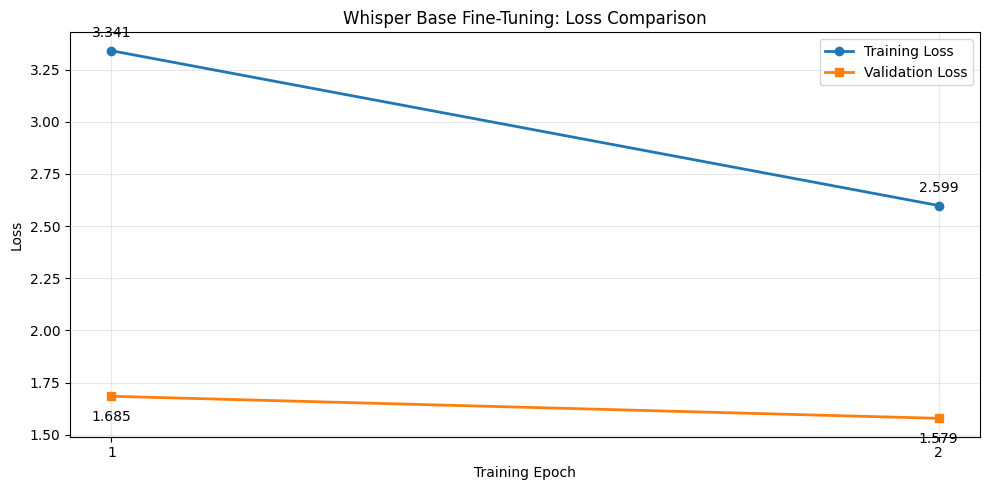

TRAINING RESULT ANALYSIS
------------------------
Training loss reduction: 0.742
Validation loss reduction: 0.106

Interpretation:
1. Training loss decreased: the model learned from training data.
2. Validation loss decreased: performance on validation data improved.
3. Both losses decreased: encouraging evidence of learning.
4. WER and CER evaluation is still required to measure transcription quality.


In [21]:
import matplotlib.pyplot as plt

# Results from your actual training
epochs = [1, 2]
training_loss = [3.340781, 2.598900]
validation_loss = [1.684710, 1.578902]

plt.figure(figsize=(10, 5))

plt.plot(
    epochs, training_loss,
    marker="o", linewidth=2,
    label="Training Loss"
)

plt.plot(
    epochs, validation_loss,
    marker="s", linewidth=2,
    label="Validation Loss"
)

# Display values on graph
for x, y in zip(epochs, training_loss):
    plt.annotate(f"{y:.3f}", (x, y), xytext=(0, 10),
                 textcoords="offset points", ha="center")

for x, y in zip(epochs, validation_loss):
    plt.annotate(f"{y:.3f}", (x, y), xytext=(0, -18),
                 textcoords="offset points", ha="center")

plt.title("Whisper Base Fine-Tuning: Loss Comparison")
plt.xlabel("Training Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Explain the result
print("TRAINING RESULT ANALYSIS")
print("------------------------")
print(f"Training loss reduction: {training_loss[0] - training_loss[-1]:.3f}")
print(f"Validation loss reduction: {validation_loss[0] - validation_loss[-1]:.3f}")

print("\nInterpretation:")
print("1. Training loss decreased: the model learned from training data.")
print("2. Validation loss decreased: performance on validation data improved.")
print("3. Both losses decreased: encouraging evidence of learning.")
print("4. WER and CER evaluation is still required to measure transcription quality.")

In [24]:
import os
import pandas as pd

TEST_CSV = f"{BASE_IN}/splits/test.csv"
TEST_DIR = f"{BASE_OUT}/test"
os.makedirs(TEST_DIR, exist_ok=True)

PILOT_TEST_CSV = f"{TEST_DIR}/pilot_test_1000.csv"

test_df = pd.read_csv(TEST_CSV)

dialects = ["ag", "be", "bs", "gr", "lu", "sg", "vs", "zh"]

selected = []

for dialect in dialects:
    group = test_df[test_df["dialect"] == dialect]

    if len(group) < 125:
        raise ValueError(
            f"{dialect} has only {len(group)} recordings. "
            "Cannot select 125."
        )

    selected.append(
        group.sample(n=125, random_state=42)
    )

test_1000 = pd.concat(selected).sample(
    frac=1, random_state=42
).reset_index(drop=True)

test_1000["audio_path"] = test_1000.apply(
    lambda row: os.path.join(
        BASE_IN,
        "converted",
        str(row["dialect"]),
        os.path.basename(
            str(row["audio_path"]).replace("\\", "/")
        )
    ),
    axis=1
)

test_1000.to_csv(PILOT_TEST_CSV, index=False)

print("TEST SET READY")
print("Total recordings:", len(test_1000))
print("\nDialect distribution:")
print(test_1000["dialect"].value_counts().sort_index())
print("\nSaved:", PILOT_TEST_CSV)

TEST SET READY
Total recordings: 1000

Dialect distribution:
dialect
ag    125
be    125
bs    125
gr    125
lu    125
sg    125
vs    125
zh    125
Name: count, dtype: int64

Saved: /content/drive/MyDrive/SwissDial_ASR_Output/test/pilot_test_1000.csv


In [25]:
import os
import time
import torch
import pandas as pd
import numpy as np
import soundfile as sf
import librosa

from transformers import WhisperForConditionalGeneration, WhisperProcessor

# Load the 1000-recording test set
TEST_CSV = f"{BASE_OUT}/test/pilot_test_1000.csv"
PREDICTION_CSV = f"{BASE_OUT}/test/model_comparison_predictions.csv"

test_df = pd.read_csv(TEST_CSV)

# Identify transcript column
possible_columns = ["text", "transcript", "transcription", "sentence"]
TEXT_COL = next(
    (c for c in possible_columns if c in test_df.columns),
    None
)

if TEXT_COL is None:
    raise ValueError(f"Transcript column not found: {list(test_df.columns)}")

# Load original Whisper Base
print("Loading original Whisper Base...")
baseline_model = WhisperForConditionalGeneration.from_pretrained(
    "openai/whisper-base"
).to("cuda")

# Configure both models for German speech transcription
for current_model in [baseline_model, fine_model]:
    current_model.generation_config.language = "german"
    current_model.generation_config.task = "transcribe"
    current_model.eval()

# Resume previously saved predictions if available
if os.path.exists(PREDICTION_CSV):
    predictions_df = pd.read_csv(PREDICTION_CSV)
    completed = set(predictions_df["row_index"].astype(int))
    print("Resuming. Already completed:", len(completed))
else:
    predictions_df = pd.DataFrame(columns=[
        "row_index", "dialect", "reference",
        "baseline_prediction", "fine_tuned_prediction",
        "baseline_seconds", "fine_tuned_seconds"
    ])
    completed = set()

def transcribe(audio_path, current_model, current_processor):
    audio, sr = sf.read(audio_path)

    if audio.ndim == 2:
        audio = audio.mean(axis=1)

    if sr != 16000:
        audio = librosa.resample(
            audio.astype(np.float32),
            orig_sr=sr,
            target_sr=16000
        )

    audio = audio.astype(np.float32)

    inputs = current_processor.feature_extractor(
        audio,
        sampling_rate=16000,
        return_tensors="pt"
    ).input_features.to("cuda")

    torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.inference_mode():
        predicted_ids = current_model.generate(
            inputs,
            max_new_tokens=225
        )

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    transcription = current_processor.batch_decode(
        predicted_ids,
        skip_special_tokens=True
    )[0]

    return transcription.strip(), elapsed


# Process both models on identical recordings
for i, row in test_df.iterrows():

    if i in completed:
        continue

    audio_path = row["audio_path"]

    if not os.path.exists(audio_path):
        raise FileNotFoundError(audio_path)

    reference = str(row[TEXT_COL])

    baseline_text, baseline_time = transcribe(
        audio_path, baseline_model, fine_processor
    )

    fine_text, fine_time = transcribe(
        audio_path, fine_model, fine_processor
    )

    predictions_df.loc[len(predictions_df)] = [
        i,
        row["dialect"],
        reference,
        baseline_text,
        fine_text,
        baseline_time,
        fine_time
    ]

    completed.add(i)

    # Save progress every 25 recordings
    if len(completed) % 25 == 0:
        predictions_df.to_csv(PREDICTION_CSV, index=False)
        print(f"Completed {len(completed)}/1000 recordings")

# Final save
predictions_df = predictions_df.sort_values("row_index")
predictions_df.to_csv(PREDICTION_CSV, index=False)

print("\nBOTH MODEL EVALUATIONS COMPLETED")
print("Total recordings:", len(predictions_df))
print("Saved predictions:", PREDICTION_CSV)

Loading original Whisper Base...


Loading weights:   0%|          | 0/245 [00:00<?, ?it/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] Both `max_ne

Completed 25/1000 recordings


[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

Completed 50/1000 recordings


... (72 outputs left out)

[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

Completed 975/1000 recordings


[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

Completed 1000/1000 recordings

BOTH MODEL EVALUATIONS COMPLETED
Total recordings: 1000
Saved predictions: /content/drive/MyDrive/SwissDial_ASR_Output/test/model_comparison_predictions.csv


In [26]:
import pandas as pd
import numpy as np
import evaluate

# Load saved predictions
PREDICTION_CSV = f"{BASE_OUT}/test/model_comparison_predictions.csv"
df = pd.read_csv(PREDICTION_CSV)

wer_metric = evaluate.load("wer")
cer_metric = evaluate.load("cer")

# Remove missing rows and ensure text values are strings
df = df.dropna(subset=[
    "reference",
    "baseline_prediction",
    "fine_tuned_prediction"
]).copy()

for col in ["reference", "baseline_prediction", "fine_tuned_prediction"]:
    df[col] = df[col].astype(str)

# Overall evaluation
references = df["reference"].tolist()
baseline_predictions = df["baseline_prediction"].tolist()
fine_predictions = df["fine_tuned_prediction"].tolist()

baseline_wer = wer_metric.compute(
    predictions=baseline_predictions,
    references=references
)

fine_wer = wer_metric.compute(
    predictions=fine_predictions,
    references=references
)

baseline_cer = cer_metric.compute(
    predictions=baseline_predictions,
    references=references
)

fine_cer = cer_metric.compute(
    predictions=fine_predictions,
    references=references
)

# Inference timing
baseline_total = df["baseline_seconds"].sum()
fine_total = df["fine_tuned_seconds"].sum()

baseline_avg = df["baseline_seconds"].mean()
fine_avg = df["fine_tuned_seconds"].mean()

# Relative WER reduction
wer_reduction = (
    (baseline_wer - fine_wer) / baseline_wer * 100
    if baseline_wer > 0 else 0
)

# Overall results
overall_results = pd.DataFrame({
    "Metric": [
        "WER (%)",
        "CER (%)",
        "Total inference time (seconds)",
        "Average inference time (seconds/audio)"
    ],
    "Original Whisper Base": [
        baseline_wer * 100,
        baseline_cer * 100,
        baseline_total,
        baseline_avg
    ],
    "Fine-tuned Whisper Base": [
        fine_wer * 100,
        fine_cer * 100,
        fine_total,
        fine_avg
    ]
})

print("========== OVERALL MODEL COMPARISON ==========")
print(overall_results.round(4).to_string(index=False))

print(f"\nRelative WER reduction: {wer_reduction:.2f}%")
print(f"Number of evaluated recordings: {len(df)}")

# Dialect-wise evaluation
dialect_results = []

for dialect in sorted(df["dialect"].unique()):
    subset = df[df["dialect"] == dialect]

    refs = subset["reference"].tolist()

    b_wer = wer_metric.compute(
        predictions=subset["baseline_prediction"].tolist(),
        references=refs
    )

    f_wer = wer_metric.compute(
        predictions=subset["fine_tuned_prediction"].tolist(),
        references=refs
    )

    b_cer = cer_metric.compute(
        predictions=subset["baseline_prediction"].tolist(),
        references=refs
    )

    f_cer = cer_metric.compute(
        predictions=subset["fine_tuned_prediction"].tolist(),
        references=refs
    )

    dialect_results.append({
        "Dialect": dialect,
        "Recordings": len(subset),
        "Baseline WER (%)": b_wer * 100,
        "Fine-tuned WER (%)": f_wer * 100,
        "Baseline CER (%)": b_cer * 100,
        "Fine-tuned CER (%)": f_cer * 100
    })

dialect_results = pd.DataFrame(dialect_results)

print("\n========== DIALECT-WISE COMPARISON ==========")
print(dialect_results.round(2).to_string(index=False))

# Save results permanently
overall_results.to_csv(
    f"{BASE_OUT}/test/overall_metrics.csv",
    index=False
)

dialect_results.to_csv(
    f"{BASE_OUT}/test/dialect_metrics.csv",
    index=False
)

print("\nResults saved successfully in Google Drive.")

========== OVERALL MODEL COMPARISON ==========
                                Metric  Original Whisper Base  Fine-tuned Whisper Base
                               WER (%)                87.2802                  77.2408
                               CER (%)                35.5391                  26.0125
        Total inference time (seconds)               193.6528                 223.9968
Average inference time (seconds/audio)                 0.1937                   0.2240

Relative WER reduction: 11.50%
Number of evaluated recordings: 1000

========== DIALECT-WISE COMPARISON ==========
Dialect  Recordings  Baseline WER (%)  Fine-tuned WER (%)  Baseline CER (%)  Fine-tuned CER (%)
     ag         125             96.94               85.60             40.24               28.76
     be         125             91.41               79.00             38.88               26.08
     bs         125             79.23               69.77             30.47               23.10
     gr         12

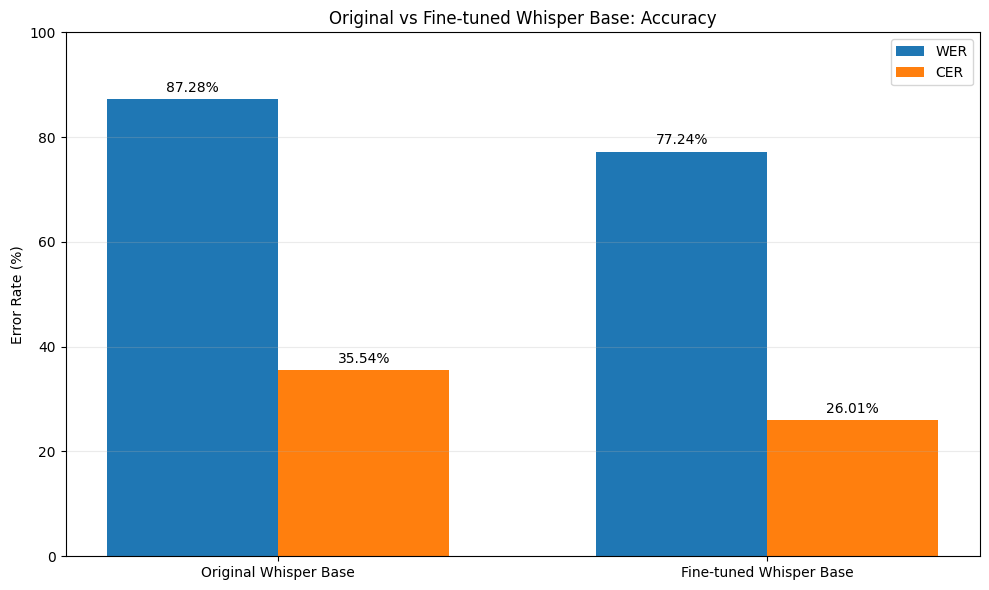

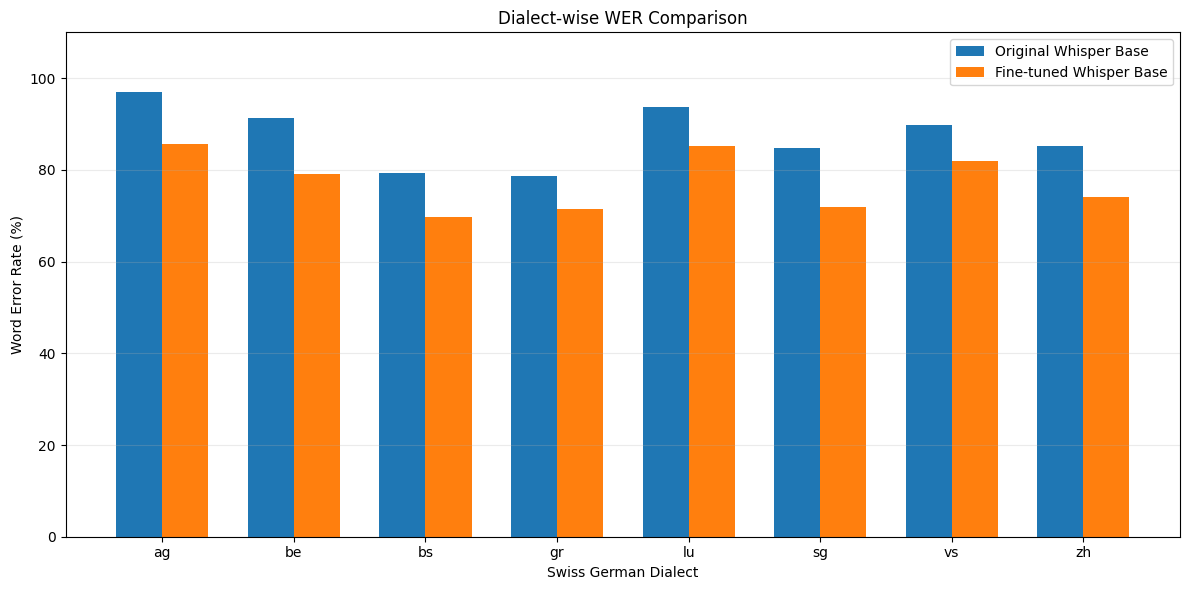

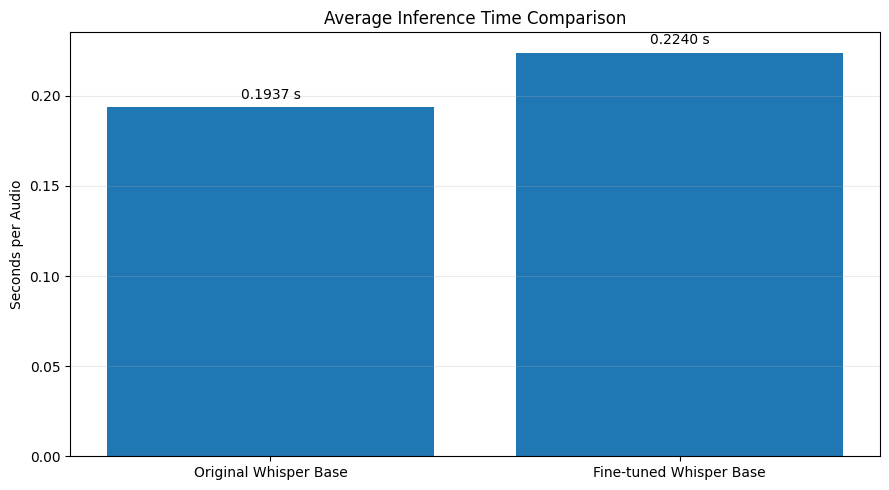

RESEARCH RESULT SUMMARY
-----------------------
WER improvement: 11.50%
CER improvement: 26.81%
Inference time increase: 15.67%

All three graphs saved in:
/content/drive/MyDrive/SwissDial_ASR_Output/graphs


In [27]:
import matplotlib.pyplot as plt
import numpy as np
import os

GRAPH_DIR = f"{BASE_OUT}/graphs"
os.makedirs(GRAPH_DIR, exist_ok=True)

# Actual overall results
models = ["Original Whisper Base", "Fine-tuned Whisper Base"]

wer = [87.2802, 77.2408]
cer = [35.5391, 26.0125]

baseline_time = 0.1936528
fine_time = 0.2239968

# Actual dialect-wise results
dialects = ["ag", "be", "bs", "gr", "lu", "sg", "vs", "zh"]

baseline_dialect_wer = [
    96.94, 91.41, 79.23, 78.62,
    93.65, 84.72, 89.71, 85.21
]

fine_dialect_wer = [
    85.60, 79.00, 69.77, 71.49,
    85.11, 71.89, 81.85, 74.05
]

# ----------------------------------
# GRAPH 1: Overall WER and CER
# ----------------------------------

x = np.arange(2)
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(
    x - width/2, wer, width,
    label="WER"
)

bars2 = ax.bar(
    x + width/2, cer, width,
    label="CER"
)

ax.set_title("Original vs Fine-tuned Whisper Base: Accuracy")
ax.set_ylabel("Error Rate (%)")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 100)
ax.legend()
ax.grid(axis="y", alpha=0.25)

ax.bar_label(bars1, fmt="%.2f%%", padding=3)
ax.bar_label(bars2, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.savefig(
    f"{GRAPH_DIR}/overall_error_comparison.png",
    dpi=300
)
plt.show()


# ----------------------------------
# GRAPH 2: Dialect-wise WER
# ----------------------------------

x = np.arange(len(dialects))

fig, ax = plt.subplots(figsize=(12, 6))

bars1 = ax.bar(
    x - width/2,
    baseline_dialect_wer,
    width,
    label="Original Whisper Base"
)

bars2 = ax.bar(
    x + width/2,
    fine_dialect_wer,
    width,
    label="Fine-tuned Whisper Base"
)

ax.set_title("Dialect-wise WER Comparison")
ax.set_xlabel("Swiss German Dialect")
ax.set_ylabel("Word Error Rate (%)")
ax.set_xticks(x)
ax.set_xticklabels(dialects)
ax.set_ylim(0, 110)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    f"{GRAPH_DIR}/dialect_wise_wer.png",
    dpi=300
)
plt.show()


# ----------------------------------
# GRAPH 3: Inference Time
# ----------------------------------

times = [baseline_time, fine_time]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(models, times)

ax.set_title("Average Inference Time Comparison")
ax.set_ylabel("Seconds per Audio")
ax.grid(axis="y", alpha=0.25)

ax.bar_label(bars, fmt="%.4f s", padding=4)

plt.tight_layout()
plt.savefig(
    f"{GRAPH_DIR}/inference_time_comparison.png",
    dpi=300
)
plt.show()


# ----------------------------------
# Save improvement summary
# ----------------------------------

print("RESEARCH RESULT SUMMARY")
print("-----------------------")

print(f"WER improvement: {(wer[0]-wer[1])/wer[0]*100:.2f}%")
print(f"CER improvement: {(cer[0]-cer[1])/cer[0]*100:.2f}%")

print(
    f"Inference time increase: "
    f"{(fine_time-baseline_time)/baseline_time*100:.2f}%"
)

print("\nAll three graphs saved in:")
print(GRAPH_DIR)

# Swiss German Automatic Speech Recognition (ASR) Using Whisper Base Fine-Tuning

## 1. Project Overview

The objective of this project is to develop and evaluate an Automatic Speech Recognition (ASR) system that can recognize spoken Swiss German and convert it into written text.

Swiss German contains several regional dialects that differ in pronunciation, vocabulary, and spelling. General-purpose speech recognition models may struggle to recognize these dialect variations accurately.

In this project, OpenAI's pre-trained Whisper Base model is fine-tuned using the SwissDial dataset to improve its ability to recognize Swiss German dialects.

The project compares the performance of:

1. **Original Whisper Base:** The pre-trained model without additional SwissDial training.
2. **Fine-tuned Whisper Base:** The same model after training on a subset of SwissDial.

Both models are evaluated using the same test recordings to ensure a fair comparison.

### Main Objectives

- Understand and process the SwissDial speech dataset.
- Fine-tune Whisper Base using Swiss German speech recordings.
- Preserve the original dialect-specific reference transcripts.
- Evaluate the original and fine-tuned models using Word Error Rate (WER) and Character Error Rate (CER).
- Compare performance across eight Swiss German dialects.
- Measure inference time and analyze the improvements and limitations.

---

## 2. Dataset Description

### Dataset: SwissDial

SwissDial is a Swiss German speech dataset containing audio recordings and corresponding text transcriptions from different Swiss German dialect regions.

The dataset includes eight dialect categories:

| Dialect Code | Dialect Region |
|---|---|
| ag | Aargau |
| be | Bern |
| bs | Basel-Stadt |
| gr | Graubünden |
| lu | Lucerne |
| sg | St. Gallen |
| vs | Valais |
| zh | Zurich |

### Dataset Components

The dataset contains:

- Audio recordings of spoken Swiss German.
- Corresponding reference transcripts.
- Dialect information.
- Sentence identifiers used to organize and split the recordings.

The audio recordings are stored in the converted audio directory, organized by dialect.

The original transcripts are retained as provided by the dataset. They are not intentionally translated into Standard German or rewritten to remove dialect-specific vocabulary.

### Original Dataset Split

The existing dataset was divided into three separate subsets:

| Dataset | Number of Recordings | Purpose |
|---|---:|---|
| Training | 18,475 | Used for model training |
| Validation | 2,319 | Used to monitor training performance |
| Test | 2,401 | Reserved for model evaluation |
| **Total** | **23,195** | |

The split was based on sentence IDs to avoid placing recordings belonging to the same sentence group in different subsets.

This helps reduce data leakage between training, validation, and testing.

**Important:** The experiment documented below uses a smaller pilot subset of the existing training and validation data. The complete original dataset split was not used for fine-tuning.

---

## 3. Experimental Data Selection

To first verify that the fine-tuning workflow worked correctly and could improve recognition performance, a smaller pilot experiment was conducted.

### Training Data

A total of **500 audio recordings** were selected from the existing training split.

The recordings were balanced across the eight dialects.

### Validation Data

A total of **100 audio recordings** were selected from the existing validation split.

These recordings were used to monitor the model's performance during training.

### Pilot Training and Validation Distribution

| Dialect | Training | Validation |
|---|---:|---:|
| ag | 63 | 13 |
| be | 63 | 13 |
| bs | 63 | 13 |
| gr | 63 | 13 |
| lu | 62 | 12 |
| sg | 62 | 12 |
| vs | 62 | 12 |
| zh | 62 | 12 |
| **Total** | **500** | **100** |

The slight differences in the number of recordings per dialect are due to distributing the available recordings as evenly as possible.

### Test Data

A separate set of **1,000 audio recordings** was selected from the original test split.

The test set contains exactly 125 recordings from each dialect.

| Dialect | Test Recordings |
|---|---:|
| ag | 125 |
| be | 125 |
| bs | 125 |
| gr | 125 |
| lu | 125 |
| sg | 125 |
| vs | 125 |
| zh | 125 |
| **Total** | **1,000** |

The remaining 1,401 recordings in the original test split were not included in this pilot evaluation.

The same 1,000 recordings were used to evaluate both the original and fine-tuned models.

This ensures that the comparison is performed on identical test data.

---

## 4. Development Environment and Hardware

The experiment was conducted using Google Colab.

### Software and Libraries

- Python
- PyTorch
- Hugging Face Transformers
- Hugging Face Datasets
- Hugging Face Evaluate
- Accelerate
- Librosa
- SoundFile
- JiWER
- NumPy
- Pandas
- Matplotlib

### Model and Hardware

| Component | Configuration |
|---|---|
| Pre-trained model | OpenAI Whisper Base |
| Model architecture | Transformer-based encoder-decoder |
| Training platform | Google Colab |
| GPU | NVIDIA Tesla T4 |
| GPU memory | 16 GB |
| PyTorch version | 2.14.1+cu130 |
| Transformers version | 4.46.3 |
| Datasets version | 3.1.0 |
| Audio sampling rate | 16,000 Hz |
| Audio channels | Mono |

The Tesla T4 GPU was provided by Google Colab. It was not the physical GPU installed in the local computer.

### Google Drive Storage

Google Drive was used to store the input dataset, processed datasets, model checkpoints, final model, predictions, and evaluation results.

Main output directory:

`MyDrive/SwissDial_ASR_Output/`

Important output locations:

- `processed/train_complete` – processed training dataset.
- `processed/validation_complete` – processed validation dataset.
- `checkpoints/whisper_base_pilot` – training checkpoints.
- `final_whisper_base_pilot` – final fine-tuned model and processor.
- `test/pilot_test_1000.csv` – selected test recordings.
- `test/model_comparison_predictions.csv` – model predictions and inference times.
- `test/overall_metrics.csv` – overall evaluation metrics.
- `test/dialect_metrics.csv` – dialect-wise evaluation metrics.

---

## 5. Audio Preprocessing

Before fine-tuning, the audio recordings were prepared for the Whisper model.

### Step 1: Loading Audio

Audio files were loaded using the SoundFile library.

### Step 2: Converting to Mono

If an audio recording contained multiple channels, the channels were averaged to produce a single-channel mono recording.

### Step 3: Resampling

Whisper expects audio sampled at 16 kHz.

Therefore, recordings with a different sampling rate were resampled to 16,000 Hz using Librosa.

### Step 4: Feature Extraction

The Whisper feature extractor converted the audio waveforms into log-Mel spectrogram features.

The resulting input feature representation had the shape:

`(80, 3000)`

This represents 80 Mel frequency channels and 3,000 time frames for the model input.

### Step 5: Text Tokenization

The corresponding reference transcripts were converted into token IDs using the Whisper tokenizer.

These token IDs were used as the target labels during model training.

### Step 6: Saving Processed Data

The processed training and validation datasets were saved in Google Drive in batches.

This allowed the processed datasets to be reused without repeating the entire preprocessing process after a Colab runtime restart.

### Preprocessing Summary

| Operation | Description |
|---|---|
| Audio loading | SoundFile |
| Channel conversion | Stereo/multichannel to mono |
| Sampling rate | 16,000 Hz |
| Feature extraction | Whisper log-Mel spectrogram |
| Feature dimensions | 80 × 3,000 |
| Text processing | Whisper tokenizer |
| Training samples | 500 |
| Validation samples | 100 |

---

## 6. Model Selection: OpenAI Whisper Base

The model selected for this experiment was `openai/whisper-base`.

Whisper is a transformer-based encoder-decoder model developed for automatic speech recognition and other speech-related tasks.

### Why Whisper Base?

- It is a pre-trained multilingual speech recognition model.
- It supports speech-to-text transcription.
- It can be fine-tuned using domain-specific audio and text data.
- Its model size is suitable for experimentation using a Google Colab GPU.

### Model Configuration

The Whisper processor was initialized with German as the language and transcription as the task.

The model generation configuration was set to:

- Language: German
- Task: Transcribe
- Forced decoder IDs: Disabled

**Important:** German was selected as the Whisper language setting because Swiss German is closely related to German and is not configured as a separate supported Whisper language. The model was trained using the Swiss German reference transcripts. The objective is to recognize the spoken dialect, not translate it into Standard German.

---

## 7. Fine-Tuning Configuration

The original Whisper Base model was fine-tuned using the 500 training recordings and 100 validation recordings.

### Training Hyperparameters

| Parameter | Value |
|---|---|
| Pre-trained model | openai/whisper-base |
| Training samples | 500 |
| Validation samples | 100 |
| Number of epochs | 2 |
| Training batch size | 4 |
| Evaluation batch size | 4 |
| Gradient accumulation steps | 2 |
| Learning rate | 0.00001 (1e-5) |
| Warmup steps | 10 |
| Mixed precision | FP16 |
| Gradient checkpointing | Enabled |
| Evaluation strategy | Every epoch |
| Checkpoint saving | Every epoch |
| Maximum saved checkpoints | 2 |
| GPU | NVIDIA Tesla T4 |

### Training Process

1. Loaded the pre-trained Whisper Base model.
2. Loaded the Whisper processor and tokenizer.
3. Prepared a custom data collator to batch audio features and text labels.
4. Configured the training arguments.
5. Initialized the Hugging Face Seq2SeqTrainer.
6. Fine-tuned the model for two epochs.
7. Evaluated the model on the validation dataset after each epoch.
8. Saved the final model and processor to Google Drive.

### Training Duration

The fine-tuning process completed successfully in approximately:

**3 minutes and 49 seconds.**

### Training and Validation Loss

| Epoch | Training Loss | Validation Loss |
|---|---:|---:|
| 1 | 3.340781 | 1.684710 |
| 2 | 2.598900 | 1.578902 |

### Loss Interpretation

- Training loss decreased from 3.340781 to 2.598900.
- Validation loss decreased from 1.684710 to 1.578902.
- The training loss decreased by approximately 22.2%.
- The validation loss decreased by approximately 6.3%.

The decreasing losses indicate that the model was learning from the training data and improving its performance on the validation data.

However, loss reduction alone does not establish transcription accuracy. Therefore, the model was evaluated separately using WER and CER on the held-out test recordings.

### Final Model Location

`MyDrive/SwissDial_ASR_Output/final_whisper_base_pilot/`

The final model and its processor were saved so that they can be loaded again without repeating fine-tuning.

---

## 8. Model Evaluation Methodology

The original Whisper Base model and the fine-tuned Whisper Base model were evaluated on the same 1,000 test recordings.

### Evaluation Steps

1. Loaded the original pre-trained Whisper Base model.
2. Loaded the fine-tuned Whisper Base model from Google Drive.
3. Loaded the same test recordings for both models.
4. Generated transcripts using both models.
5. Compared each prediction with its original reference transcript.
6. Calculated WER and CER.
7. Calculated total and average inference time.
8. Calculated metrics separately for all eight dialects.

The predictions were saved periodically to Google Drive to prevent losing completed evaluation results if the Colab session was interrupted.

### Evaluation Metrics

#### A. Word Error Rate (WER)

WER measures the number of word-level errors in a predicted transcript compared with the reference transcript.

Formula:

WER = (S + D + I) / N

Where:

- S = Number of substitutions.
- D = Number of deletions.
- I = Number of insertions.
- N = Total number of words in the reference transcript.

A lower WER indicates better word recognition.

#### B. Character Error Rate (CER)

CER measures the character-level differences between the predicted transcript and the reference transcript.

Formula:

CER = (Character Substitutions + Character Deletions + Character Insertions) / Total Reference Characters

A lower CER indicates better character-level transcription accuracy.

#### C. Inference Time

Inference time measures how long the model takes to generate a transcription.

Both total inference time and average inference time per audio recording were measured.

The recorded inference time covers GPU transcription generation. It does not include the complete time required for reading files, audio resampling, and feature extraction.

---

## 9. Overall Evaluation Results

The following results were obtained by evaluating both models on the same 1,000 Swiss German recordings.

### Overall Performance Comparison

| Metric | Original Whisper Base | Fine-Tuned Whisper Base |
|---|---:|---:|
| Number of recordings | 1,000 | 1,000 |
| WER | 87.2802% | 77.2408% |
| CER | 35.5391% | 26.0125% |
| Total inference time | 193.6528 sec | 223.9968 sec |
| Average inference time | 0.1937 sec | 0.2240 sec |

### WER Improvement

Original WER: 87.2802%

Fine-tuned WER: 77.2408%

Absolute improvement:

87.2802 - 77.2408 = 10.0394 percentage points.

Relative WER reduction:

((87.2802 - 77.2408) / 87.2802) × 100

**Relative WER reduction = 11.50%**

This means that fine-tuning reduced the word error rate by approximately 11.50% relative to the original model.

### CER Improvement

Original CER: 35.5391%

Fine-tuned CER: 26.0125%

Absolute improvement:

35.5391 - 26.0125 = 9.5266 percentage points.

Relative CER reduction:

((35.5391 - 26.0125) / 35.5391) × 100

**Relative CER reduction = approximately 26.81%**

This indicates a substantial improvement in character-level transcription performance.

### Inference Time Comparison

Original average inference time: 0.1937 seconds per recording.

Fine-tuned average inference time: 0.2240 seconds per recording.

The fine-tuned model took approximately 0.0303 seconds more per recording.

This is an increase of approximately 15.7% in the measured inference time.

The fine-tuned model improved transcription accuracy, but it did not improve inference speed.

---

## 10. Dialect-Wise Evaluation Results

To understand how the model performs across different Swiss German dialects, WER and CER were calculated separately for each dialect.

Each dialect contains 125 test recordings.

### Dialect-Wise WER and CER

| Dialect | Recordings | Original WER | Fine-Tuned WER | Original CER | Fine-Tuned CER |
|---|---:|---:|---:|---:|---:|
| ag | 125 | 96.94% | 85.60% | 40.24% | 28.76% |
| be | 125 | 91.41% | 79.00% | 38.88% | 26.08% |
| bs | 125 | 79.23% | 69.77% | 30.47% | 23.10% |
| gr | 125 | 78.62% | 71.49% | 30.56% | 23.74% |
| lu | 125 | 93.65% | 85.11% | 41.00% | 31.36% |
| sg | 125 | 84.72% | 71.89% | 33.42% | 24.15% |
| vs | 125 | 89.71% | 81.85% | 37.71% | 27.30% |
| zh | 125 | 85.21% | 74.05% | 31.89% | 23.39% |

### Dialect-Wise Observations

- All eight dialects showed improvement in WER after fine-tuning.
- All eight dialects also showed improvement in CER.
- The largest absolute WER improvement occurred in St. Gallen (sg), with an improvement of 12.83 percentage points.
- Bern (be) showed the second-largest WER improvement, at 12.41 percentage points.
- Aargau (ag) had the highest fine-tuned WER at 85.60%.
- Lucerne (lu) had the highest fine-tuned CER at 31.36%.
- Basel-Stadt (bs) achieved the lowest fine-tuned WER at 69.77%.

These results show that fine-tuning helped across all eight dialects, although recognition performance still varies considerably between dialect regions.

---

## 11. Prediction Storage and Result Files

The generated predictions and evaluation metrics were saved in Google Drive.

### Prediction File

`test/model_comparison_predictions.csv`

The file contains the following columns:

| Column | Description |
|---|---|
| row_index | Original test-record index |
| dialect | Swiss German dialect code |
| reference | Original reference transcript |
| baseline_prediction | Transcript generated by original Whisper Base |
| fine_tuned_prediction | Transcript generated by fine-tuned Whisper Base |
| baseline_seconds | Original model inference time |
| fine_tuned_seconds | Fine-tuned model inference time |

### Evaluation Files

- `test/overall_metrics.csv` – overall WER, CER, and inference-time results.
- `test/dialect_metrics.csv` – dialect-specific WER and CER results.
- `test/pilot_test_1000.csv` – selected 1,000 test recordings.

### Model Files

- `final_whisper_base_pilot/` – saved fine-tuned model and processor.
- `checkpoints/whisper_base_pilot/` – intermediate training checkpoints.

---

## 12. Key Findings

The pilot experiment demonstrated that fine-tuning Whisper Base using SwissDial can improve Swiss German speech recognition.

The main findings are:

1. Fine-tuning reduced overall WER from 87.28% to 77.24%.
2. Relative WER reduction was approximately 11.50%.
3. CER decreased from 35.54% to 26.01%.
4. Relative CER reduction was approximately 26.81%.
5. Every one of the eight evaluated dialects showed improvement in both WER and CER.
6. St. Gallen showed the largest absolute WER improvement.
7. The fine-tuned model required slightly more inference time than the original model.
8. Despite the improvement, the fine-tuned WER of 77.24% is still high, indicating that further training and experimentation are necessary.

---

## 13. Limitations of the Current Experiment

This experiment is a pilot study and should not be treated as the final performance benchmark.

### Limited Training Data

Only 500 training recordings and 100 validation recordings were used. The original training split contains 18,475 recordings.

Using more training data may improve generalization across dialects.

### Limited Training Duration

The model was fine-tuned for only two epochs. Additional training experiments may improve results, but the risk of overfitting must be monitored.

### Remaining Recognition Errors

The fine-tuned model still has a WER of 77.24%. This indicates that many words are still incorrectly recognized.

### Dialect Variations

Swiss German dialects differ significantly in pronunciation, vocabulary, and spelling. Some dialects remain more challenging than others.

### Inference Time

The fine-tuned model took slightly longer to generate predictions. Further optimization may be required for faster transcription.

### Test Set Coverage

Only 1,000 of the original 2,401 test recordings were used for this pilot evaluation. The remaining test recordings have not yet been evaluated in this experiment.

### Transcript Normalization

The experiment compares predictions with the original reference transcripts. Any changes in capitalization, punctuation, spelling, or dialect-specific word forms can affect WER and CER. The evaluation should therefore be interpreted as performance against the dataset's original transcription conventions.

---

## 14. Future Improvements

The following experiments can be performed to improve the system:

1. Increase the training dataset from 500 recordings to several thousand recordings.
2. Increase the number of training epochs while monitoring validation performance.
3. Experiment with different learning rates and batch sizes.
4. Perform detailed error analysis to identify common recognition mistakes.
5. Examine whether the model preserves dialect-specific vocabulary and spelling.
6. Evaluate performance on the complete 2,401-recording test set.
7. Compare Whisper Base with other Whisper model sizes if GPU resources permit.
8. Explore data augmentation techniques to improve robustness.
9. Investigate decoding parameters and inference optimizations.
10. Compare raw WER/CER with carefully defined normalized metrics as a secondary analysis.

All future experiments should preserve the separation between training, validation, and test data.

---

## 15. Conclusion

This project investigated the use of transfer learning to improve Swiss German Automatic Speech Recognition using OpenAI Whisper Base and the SwissDial dataset.

A pilot dataset containing 500 training recordings, 100 validation recordings, and 1,000 test recordings was prepared across eight Swiss German dialects.

The pre-trained Whisper Base model was fine-tuned for two epochs using a Google Colab Tesla T4 GPU.

The results showed that fine-tuning improved overall WER from 87.28% to 77.24% and CER from 35.54% to 26.01%.

The fine-tuned model also demonstrated improvements across all eight dialects.

These findings suggest that adapting a multilingual pre-trained speech recognition model to Swiss German speech data can improve recognition performance.

However, the remaining WER is relatively high, and the current experiment is limited by the small training subset and short training duration.

The next stage of the project should focus on increasing the training data, conducting detailed transcription error analysis, and evaluating the final model on the complete held-out test set.

**Overall conclusion:** Fine-tuning Whisper Base using SwissDial produced a measurable improvement in Swiss German speech recognition during the pilot experiment, providing a foundation for further model development and evaluation.

---

## 16. Dataset and Model References

- **SwissDial dataset:** Cite the original SwissDial dataset publication and the official dataset/project page used to obtain the recordings.
- **Whisper:** Radford et al., *Robust Speech Recognition via Large-Scale Weak Supervision*, 2022.
- **Pre-trained model:** `openai/whisper-base`, available through Hugging Face.
- **Transformers documentation:** Hugging Face Transformers documentation.
- **Evaluation metrics:** WER and CER calculated using the Hugging Face Evaluate library and JiWER.

### Dataset License

SwissDial is distributed under the Creative Commons Attribution-NonCommercial 4.0 International (CC BY-NC 4.0) license, as identified for this dataset.

Appropriate attribution must be provided, and the non-commercial restriction must be respected when using or redistributing the dataset.

---

**Experiment Status: Pilot Fine-Tuning and 1,000-Recording Evaluation Completed**

**Training:** Completed  
**Validation:** Completed  
**Fine-tuned model saving:** Completed  
**Baseline evaluation:** Completed  
**Fine-tuned evaluation:** Completed  
**Overall WER/CER comparison:** Completed  
**Eight-dialect comparison:** Completed  
**Full 2,401-recording test evaluation:** Not yet completed  
**Final large-scale training:** Not yet completed